In [12]:
pip install tensorflow

Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install tensorflow pandas numpy matplotlib opencv-python scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd

data = pd.read_csv("fer2013.csv")

print(data.head())
print(data.shape)

   emotion                                             pixels     Usage
0        0  70 80 82 72 58 58 60 63 54 58 60 48 89 115 121...  Training
1        0  151 150 147 155 148 133 111 140 170 174 182 15...  Training
2        2  231 212 156 164 174 138 161 173 182 200 106 38...  Training
3        4  24 32 36 30 32 23 19 20 30 41 21 22 32 34 21 1...  Training
4        6  4 0 0 0 0 0 0 0 0 0 0 0 3 15 23 28 48 50 58 84...  Training
(35887, 3)


In [5]:
import numpy as np

pixels = data['pixels'].tolist()

images = []

for pixel_sequence in pixels:
    image = np.array(pixel_sequence.split(), dtype='float32')
    image = image.reshape(48,48)
    images.append(image)

images = np.array(images)

In [6]:
images = images.reshape(-1,48,48,1)
images = images / 255.0

In [7]:
from tensorflow.keras.utils import to_categorical

labels = data['emotion'].values
labels = to_categorical(labels, num_classes=7)

In [8]:
train_images = images[data['Usage']=="Training"]
train_labels = labels[data['Usage']=="Training"]

test_images = images[data['Usage']=="PublicTest"]
test_labels = labels[data['Usage']=="PublicTest"]

In [10]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Input

model = Sequential()

model.add(Input(shape=(48,48,1)))

model.add(Conv2D(32,(3,3),activation='relu'))
model.add(MaxPooling2D((2,2)))

model.add(Conv2D(64,(3,3),activation='relu'))
model.add(MaxPooling2D((2,2)))

model.add(Conv2D(128,(3,3),activation='relu'))

model.add(Flatten())

model.add(Dense(128,activation='relu'))

model.add(Dense(7,activation='softmax'))

In [13]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [14]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d_3 (Conv2D)                    │ (None, 46, 46, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 23, 23, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 21, 21, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 10, 10, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 8, 8, 128)           │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ flatten_1 (Flatten)                  │ (None, 8192)                │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 128)                 │       1,048,704 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_3 (Dense)                      │ (None, 7)                   │             903 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,142,279 (4.36 MB)

 Trainable params: 1,142,279 (4.36 MB)

 Non-trainable params: 0 (0.00 B)

In [16]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

In [17]:
history = model.fit(
    train_images,
    train_labels,
    epochs=30,
    batch_size=64,
    validation_data=(test_images,test_labels)
)

Epoch 1/30
449/449 ━━━━━━━━━━━━━━━━━━━━ 80s 170ms/step - accuracy: 0.3563 - loss: 1.6253 - val_accuracy: 0.4458 - val_loss: 1.4507
Epoch 2/30
449/449 ━━━━━━━━━━━━━━━━━━━━ 62s 138ms/step - accuracy: 0.4755 - loss: 1.3693 - val_accuracy: 0.5004 - val_loss: 1.3059
Epoch 3/30
449/449 ━━━━━━━━━━━━━━━━━━━━ 87s 148ms/step - accuracy: 0.5306 - loss: 1.2321 - val_accuracy: 0.5238 - val_loss: 1.2581
Epoch 4/30
449/449 ━━━━━━━━━━━━━━━━━━━━ 71s 158ms/step - accuracy: 0.5706 - loss: 1.1347 - val_accuracy: 0.5347 - val_loss: 1.2196
Epoch 5/30
449/449 ━━━━━━━━━━━━━━━━━━━━ 51s 113ms/step - accuracy: 0.6046 - loss: 1.0486 - val_accuracy: 0.5559 - val_loss: 1.1856
Epoch 6/30
449/449 ━━━━━━━━━━━━━━━━━━━━ 117s 191ms/step - accuracy: 0.6467 - loss: 0.9522 - val_accuracy: 0.5553 - val_loss: 1.2349
Epoch 7/30
449/449 ━━━━━━━━━━━━━━━━━━━━ 86s 192ms/step - accuracy: 0.6854 - loss: 0.8543 - val_accuracy: 0.5525 - val_loss: 1.2649
Epoch 8/30
449/449 ━━━━━━━━━━━━━━━━━━━━ 163s 238ms/step - accuracy: 0.7243 - loss:

In [22]:
model.save("emotion_model.keras")
print("Model saved successfully!")

Model saved successfully!


In [ ]:
import cv2
import numpy as np
from tensorflow.keras.models import load_model

model = load_model("emotion_model.keras")

emotion_labels = [
    "Angry",
    "Disgust",
    "Fear",
    "Happy",
    "Sad",
    "Surprise",
    "Neutral"
]

face_cascade = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)

cap = cv2.VideoCapture(0)


while True:

    ret, frame = cap.read()

    gray = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY)

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.3,
        minNeighbors=5
    )

    for (x, y, w, h) in faces:

        face = gray[y:y+h, x:x+w]

        face = cv2.resize(face, (48,48))

        face = face / 255.0

        face = np.reshape(face, (1,48,48,1))

        prediction = model.predict(face)

        emotion = emotion_labels[np.argmax(prediction)]

        cv2.rectangle(frame,(x,y),(x+w,y+h),(0,255,0),2)

        cv2.putText(
            frame,
            emotion,
            (x,y-10),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.9,
            (0,255,0),
            2
        )

    cv2.imshow("Real-Time Emotion Detector", frame)

    if cv2.waitKey(1) & 0xFF == ord('q'):
        break


cap.release()
cv2.destroyAllWindows()

In [49]:
test_loss, test_accuracy = model.evaluate(test_images, test_labels)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)


113/113 ━━━━━━━━━━━━━━━━━━━━ 5s 32ms/step - accuracy: 0.5425 - loss: 4.1896
Test Loss: 4.18963098526001
Test Accuracy: 0.5424909591674805


In [55]:
predictions = model.predict(test_images)

predicted_classes = np.argmax(predictions, axis=1)
true_classes = np.argmax(test_labels, axis=1)

113/113 ━━━━━━━━━━━━━━━━━━━━ 5s 44ms/step


In [51]:
pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [52]:
from sklearn.metrics import classification_report

print(classification_report(true_classes, predicted_classes))

              precision    recall  f1-score   support

           0       0.43      0.45      0.44       467
           1       0.64      0.45      0.53        56
           2       0.37      0.39      0.38       496
           3       0.75      0.74      0.74       895
           4       0.44      0.43      0.44       653
           5       0.69      0.72      0.70       415
           6       0.47      0.46      0.47       607

    accuracy                           0.54      3589
   macro avg       0.54      0.52      0.53      3589
weighted avg       0.54      0.54      0.54      3589



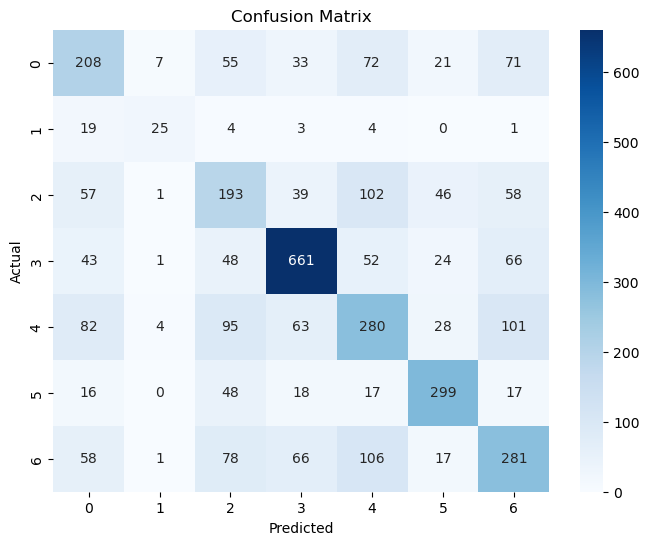

In [53]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(true_classes, predicted_classes)

plt.figure(figsize=(8,6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

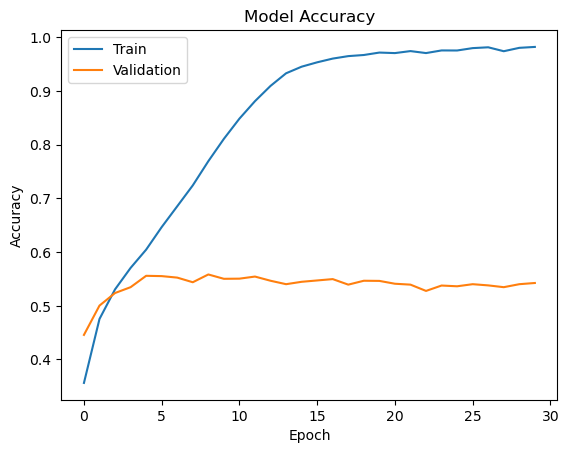

In [54]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

plt.title("Model Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")

plt.legend(["Train","Validation"])

plt.show()